In [2]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
from torch.ao.quantization import quantize_dynamic

from codecarbon import EmissionsTracker

In [5]:
import torch
import torch.nn as nn
import torchvision
from torch.ao.quantization import quantize_dynamic
from torch.nn.utils import prune

In [6]:
baseline_resnet = torchvision.models.resnet18(weights=None)
baseline_resnet.fc = nn.Linear(512, 10)

baseline_resnet.load_state_dict(
    torch.load("baseline_resnet18.pth", map_location="cpu")
)

baseline_resnet.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [7]:
pruned_resnet = torchvision.models.resnet18(weights=None)
pruned_resnet.fc = nn.Linear(512, 10)

# Apply the same pruning structure used during training
for module in pruned_resnet.modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        prune.l1_unstructured(module, name="weight", amount=0.2)

# Load the saved weights
pruned_resnet.load_state_dict(
    torch.load("pruned_resnet18.pth", map_location="cpu")
)

# Remove pruning reparameterization
for module in pruned_resnet.modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        try:
            prune.remove(module, "weight")
        except ValueError:
            pass

pruned_resnet.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [8]:
quantized_resnet = torchvision.models.resnet18(weights=None)
quantized_resnet.fc = nn.Linear(512, 10)

# Apply dynamic quantization
quantized_resnet = quantize_dynamic(
    quantized_resnet,
    {nn.Linear},
    dtype=torch.qint8
)

# Load the quantized weights
quantized_resnet.load_state_dict(
    torch.load("quantized_resnet18.pth", map_location="cpu")
)

quantized_resnet.eval()

C:\Users\alyss\AppData\Local\Temp\ipykernel_17264\43848170.py:5: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_resnet = quantize_dynamic(
C:\Users\alyss\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\_utils.py:455: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This s

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [9]:
models_to_benchmark = {
    "Baseline ResNet-18": baseline_resnet,
    "20% Pruned ResNet-18": pruned_resnet,
    "Quantized ResNet-18": quantized_resnet
}

In [10]:
for name, model in models_to_benchmark.items():
    print(f"{name} loaded successfully.")

Baseline ResNet-18 loaded successfully.
20% Pruned ResNet-18 loaded successfully.
Quantized ResNet-18 loaded successfully.


## Controlled ResNet-18 Energy Benchmark

The baseline, 20% pruned, and dynamically quantized ResNet-18 models are evaluated under an identical CPU inference workload using CodeCarbon. Each model is benchmarked for the same fixed duration to enable comparison of energy consumption, carbon emissions, and inference throughput under controlled hardware conditions.

The resulting measurements are used to examine whether model optimisation techniques translate into practical environmental and computational benefits and provide the basis for subsequent financial cost estimation.

In [11]:
import time
import pandas as pd
import torch

# Ensure consistent CPU benchmarking
torch.set_num_threads(1)

# Fixed synthetic CIFAR-10 input
benchmark_input = torch.randn(1, 3, 32, 32)

def benchmark_inference(model, input_tensor, warmup_runs=20, timed_runs=200):
    model.eval()

    # Warm-up
    with torch.no_grad():
        for _ in range(warmup_runs):
            _ = model(input_tensor)

    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(timed_runs):
            _ = model(input_tensor)

    end = time.perf_counter()

    average_latency = ((end - start) / timed_runs) * 1000

    return average_latency

In [12]:
benchmark_results = []

for model_name, model in models_to_benchmark.items():

    latency = benchmark_inference(model, benchmark_input)

    benchmark_results.append({
        "Model": model_name,
        "Average Latency (ms)": latency
    })

resnet_benchmark = pd.DataFrame(benchmark_results)

resnet_benchmark

,Model,Average Latency (ms)
0,Baseline ResNet-18,11.951663
1,20% Pruned ResNet-18,10.793239
2,Quantized ResNet-18,10.961216


In [16]:
resnet_benchmark.to_csv(
    "resnet_inference_benchmark.csv",
    index=False
)

In [17]:
import time
import pandas as pd
from codecarbon import EmissionsTracker

benchmark_duration_seconds = 60

energy_benchmark_results = []

In [18]:
tracker_results = []

for model_name, model in models_to_benchmark.items():

    print(f"\nBenchmarking: {model_name}")

    tracker = EmissionsTracker(
        measure_power_secs=1,
        log_level="error"
    )

    tracker.start()

    inference_count = 0
    start_time = time.perf_counter()

    with torch.no_grad():
        while (time.perf_counter() - start_time) < benchmark_duration_seconds:
            _ = model(benchmark_input)
            inference_count += 1

    emissions = tracker.stop()

    actual_duration = time.perf_counter() - start_time

    tracker_results.append({
        "Model": model_name,
        "Inference Count": inference_count,
        "Benchmark Duration (s)": actual_duration,
        "Throughput (inf/s)": inference_count / actual_duration,
        "CO2 Emissions (kg)": emissions
    })

    print(f"Completed {inference_count} inferences.")

[codecarbon WARNING @ 21:37:29] Multiple instances of codecarbon are allowed to run at the same time.



Benchmarking: Baseline ResNet-18
Completed 6792 inferences.

Benchmarking: 20% Pruned ResNet-18
Completed 6593 inferences.

Benchmarking: Quantized ResNet-18
Completed 6560 inferences.


In [19]:
resnet_energy_benchmark = pd.DataFrame(tracker_results)

resnet_energy_benchmark

,Model,Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg)
0,Baseline ResNet-18,6792,60.564275,112.145319,0.000024
1,20% Pruned ResNet-18,6593,60.538643,108.905645,0.000024
2,Quantized ResNet-18,6560,60.532234,108.372012,0.000024


In [20]:
resnet_energy_benchmark.to_csv(
    "resnet_energy_benchmark.csv",
    index=False
)

In [21]:
resnet_results = pd.merge(
    resnet_benchmark,
    resnet_energy_benchmark,
    on="Model"
)

resnet_results

,Model,Average Latency (ms),Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg)
0,Baseline ResNet-18,11.951663,6792,60.564275,112.145319,0.000024
1,20% Pruned ResNet-18,10.793239,6593,60.538643,108.905645,0.000024
2,Quantized ResNet-18,10.961216,6560,60.532234,108.372012,0.000024


In [23]:
codecarbon = pd.read_csv("emissions.csv")

codecarbon

,timestamp,project_name,run_id,experiment_id,duration,emissions,emissions_rate,cpu_power,gpu_power,ram_power,...,latitude,ram_total_size,tracking_mode,cpu_utilization_percent,gpu_utilization_percent,ram_utilization_percent,ram_used_gb,on_cloud,pue,wue
0,2026-06-01T15:50:50,codecarbon,bb3f16cb-30c5-4f1e-b1a6-6cd887b34580,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,0.004533,9.758321e-09,2.152883e-06,49.699122,0.0,38.0,...,53.7426,112.000000,machine,0.000000,0,0.000000,0.000000,N,1.0,0.0
1,2026-07-19T21:38:41,codecarbon,20e10fe0-27ba-489b-9a10-a400880a32b1,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,61.510749,2.388080e-05,3.882379e-07,1.513840,0.0,10.0,...,51.4647,13.849052,machine,1.694915,0,79.223729,10.970049,N,1.0,0.0
2,2026-07-19T21:39:48,codecarbon,57d36dee-bc74-48be-8929-9d279cd0de35,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,61.511865,2.391916e-05,3.888544e-07,1.535169,0.0,10.0,...,51.4647,13.849052,machine,1.130508,0,78.518644,10.873451,N,1.0,0.0
3,2026-07-19T21:40:55,codecarbon,292c8d30-0f70-4f57-9357-3595a9ccff94,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,61.504989,2.387683e-05,3.882096e-07,1.511243,0.0,10.0,...,51.4647,13.849052,machine,1.694915,0,77.415254,10.720646,N,1.0,0.0


In [24]:
codecarbon = pd.read_csv("emissions.csv")

codecarbon = codecarbon.iloc[1:].reset_index(drop=True)

codecarbon[[
    "duration",
    "energy_consumed",
    "emissions",
    "cpu_energy",
    "ram_energy"
]]

,duration,energy_consumed,emissions,cpu_energy,ram_energy
0,61.510749,0.000101,0.000024,0.000013,0.000087
1,61.511865,0.000101,0.000024,0.000013,0.000087
2,61.504989,0.000100,0.000024,0.000013,0.000087


In [25]:
codecarbon["Model"] = [
    "Baseline ResNet-18",
    "20% Pruned ResNet-18",
    "Quantized ResNet-18"
]

codecarbon

,timestamp,project_name,run_id,experiment_id,duration,emissions,emissions_rate,cpu_power,gpu_power,ram_power,...,ram_total_size,tracking_mode,cpu_utilization_percent,gpu_utilization_percent,ram_utilization_percent,ram_used_gb,on_cloud,pue,wue,Model
0,2026-07-19T21:38:41,codecarbon,20e10fe0-27ba-489b-9a10-a400880a32b1,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,61.510749,0.000024,3.882379e-07,1.513840,0.0,10.0,...,13.849052,machine,1.694915,0,79.223729,10.970049,N,1.0,0.0,Baseline ResNet-18
1,2026-07-19T21:39:48,codecarbon,57d36dee-bc74-48be-8929-9d279cd0de35,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,61.511865,0.000024,3.888544e-07,1.535169,0.0,10.0,...,13.849052,machine,1.130508,0,78.518644,10.873451,N,1.0,0.0,20% Pruned ResNet-18
2,2026-07-19T21:40:55,codecarbon,292c8d30-0f70-4f57-9357-3595a9ccff94,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,61.504989,0.000024,3.882096e-07,1.511243,0.0,10.0,...,13.849052,machine,1.694915,0,77.415254,10.720646,N,1.0,0.0,Quantized ResNet-18


In [26]:
resnet_results = pd.merge(
    resnet_results,
    codecarbon[[
        "Model",
        "energy_consumed",
        "cpu_energy",
        "ram_energy"
    ]],
    on="Model"
)

resnet_results

,Model,Average Latency (ms),Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg),Energy per Million Inferences (kWh),energy_consumed,cpu_energy,ram_energy
0,Baseline ResNet-18,11.951663,6792,60.564275,112.145319,0.000024,0.0,0.000101,0.000013,0.000087
1,20% Pruned ResNet-18,10.793239,6593,60.538643,108.905645,0.000024,0.0,0.000101,0.000013,0.000087
2,Quantized ResNet-18,10.961216,6560,60.532234,108.372012,0.000024,0.0,0.000100,0.000013,0.000087


In [27]:
resnet_results["Energy per Million Inferences (kWh)"] = (
    resnet_results["energy_consumed"]
    / resnet_results["Inference Count"]
) * 1_000_000

resnet_results["CO2 per Million Inferences (kg)"] = (
    resnet_results["CO2 Emissions (kg)"]
    / resnet_results["Inference Count"]
) * 1_000_000

resnet_results

,Model,Average Latency (ms),Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg),Energy per Million Inferences (kWh),energy_consumed,cpu_energy,ram_energy,CO2 per Million Inferences (kg)
0,Baseline ResNet-18,11.951663,6792,60.564275,112.145319,0.000024,0.014799,0.000101,0.000013,0.000087,0.003516
1,20% Pruned ResNet-18,10.793239,6593,60.538643,108.905645,0.000024,0.015270,0.000101,0.000013,0.000087,0.003628
2,Quantized ResNet-18,10.961216,6560,60.532234,108.372012,0.000024,0.015320,0.000100,0.000013,0.000087,0.003640


In [28]:
resnet_results = resnet_results.rename(columns={
    "energy_consumed": "Energy Consumed (kWh)",
    "cpu_energy": "CPU Energy (kWh)",
    "ram_energy": "RAM Energy (kWh)"
})

# Financial Analysis

### Electricity prices

In [29]:
electricity_prices = {
    "Low (£0.10/kWh)": 0.10,
    "Medium (£0.20/kWh)": 0.20,
    "High (£0.30/kWh)": 0.30
}

### Deployment workloads

In [30]:
deployment_sizes = {
    "1 Million": 1_000_000,
    "100 Million": 100_000_000,
    "1 Billion": 1_000_000_000
}

### Calculate operational costs

In [31]:
financial_results = []

for _, row in resnet_results.iterrows():

    energy_per_million = row["Energy per Million Inferences (kWh)"]

    for workload_name, workload in deployment_sizes.items():

        total_energy = energy_per_million * (workload / 1_000_000)

        for price_name, price in electricity_prices.items():

            financial_results.append({
                "Model": row["Model"],
                "Deployment": workload_name,
                "Electricity Price": price_name,
                "Energy Required (kWh)": total_energy,
                "Estimated Cost (£)": total_energy * price
            })

financial_results = pd.DataFrame(financial_results)

financial_results

,Model,Deployment,Electricity Price,Energy Required (kWh),Estimated Cost (£)
0,Baseline ResNet-18,1 Million,Low (£0.10/kWh),0.014799,0.001480
1,Baseline ResNet-18,1 Million,Medium (£0.20/kWh),0.014799,0.002960
2,Baseline ResNet-18,1 Million,High (£0.30/kWh),0.014799,0.004440
3,Baseline ResNet-18,100 Million,Low (£0.10/kWh),1.479874,0.147987
4,Baseline ResNet-18,100 Million,Medium (£0.20/kWh),1.479874,0.295975
5,Baseline ResNet-18,100 Million,High (£0.30/kWh),1.479874,0.443962
6,Baseline ResNet-18,1 Billion,Low (£0.10/kWh),14.798745,1.479874
7,Baseline ResNet-18,1 Billion,Medium (£0.20/kWh),14.798745,2.959749
8,Baseline ResNet-18,1 Billion,High (£0.30/kWh),14.798745,4.439623
9,20% Pruned ResNet-18,1 Million,Low (£0.10/kWh),0.015270,0.001527


In [32]:
financial_results.to_csv(
    "resnet_financial_analysis.csv",
    index=False
)

### Cost Difference vs Baseline

In [33]:
baseline = financial_results[
    financial_results["Model"] == "Baseline ResNet-18"
].copy()

comparison = financial_results.merge(
    baseline[
        [
            "Deployment",
            "Electricity Price",
            "Estimated Cost (£)"
        ]
    ],
    on=["Deployment", "Electricity Price"],
    suffixes=("", "_Baseline")
)

comparison["Cost Difference (£)"] = (
    comparison["Estimated Cost (£)"] -
    comparison["Estimated Cost (£)_Baseline"]
)

comparison

,Model,Deployment,Electricity Price,Energy Required (kWh),Estimated Cost (£),Estimated Cost (£)_Baseline,Cost Difference (£)
0,Baseline ResNet-18,1 Million,Low (£0.10/kWh),0.014799,0.001480,0.001480,0.000000
1,Baseline ResNet-18,1 Million,Medium (£0.20/kWh),0.014799,0.002960,0.002960,0.000000
2,Baseline ResNet-18,1 Million,High (£0.30/kWh),0.014799,0.004440,0.004440,0.000000
3,Baseline ResNet-18,100 Million,Low (£0.10/kWh),1.479874,0.147987,0.147987,0.000000
4,Baseline ResNet-18,100 Million,Medium (£0.20/kWh),1.479874,0.295975,0.295975,0.000000
5,Baseline ResNet-18,100 Million,High (£0.30/kWh),1.479874,0.443962,0.443962,0.000000
6,Baseline ResNet-18,1 Billion,Low (£0.10/kWh),14.798745,1.479874,1.479874,0.000000
7,Baseline ResNet-18,1 Billion,Medium (£0.20/kWh),14.798745,2.959749,2.959749,0.000000
8,Baseline ResNet-18,1 Billion,High (£0.30/kWh),14.798745,4.439623,4.439623,0.000000
9,20% Pruned ResNet-18,1 Million,Low (£0.10/kWh),0.015270,0.001527,0.001480,0.000047


In [34]:
resnet_results.to_csv(
    "resnet_final_results.csv",
    index=False
)

comparison.to_csv(
    "resnet_financial_analysis.csv",
    index=False
)

# EfficientNet-B0 Practical and Financial Implications

## Import Required Libraries

In [6]:
import torch
import torch.nn as nn
import torchvision
from torch.ao.quantization import quantize_dynamic

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from codecarbon import EmissionsTracker

## Load Baseline EfficientNet-B0

In [7]:
baseline_efficientnet = torchvision.models.efficientnet_b0(weights=None)

baseline_efficientnet.classifier[1] = nn.Linear(
    baseline_efficientnet.classifier[1].in_features,
    10
)

baseline_efficientnet.load_state_dict(
    torch.load("baseline_efficientnet_b0.pth", map_location="cpu")
)

baseline_efficientnet.eval()

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          

## Create Quantized EfficientNet-B0

Dynamic post-training quantization is applied to the trained baseline EfficientNet-B0 model. Only the linear classifier layer is quantized because the selected dynamic quantization method supports linear layers on the CPU.

In [8]:
import copy

quantized_efficientnet = copy.deepcopy(baseline_efficientnet)

quantized_efficientnet = quantize_dynamic(
    quantized_efficientnet,
    {nn.Linear},
    dtype=torch.qint8
)

quantized_efficientnet.eval()

print("Quantized EfficientNet-B0 created successfully.")

Quantized EfficientNet-B0 created successfully.


C:\Users\alyss\AppData\Local\Temp\ipykernel_18092\2713180982.py:5: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_efficientnet = quantize_dynamic(


## Create Model Dictionary

In [9]:
models_to_benchmark = {
    "Baseline EfficientNet-B0": baseline_efficientnet,
    "Quantized EfficientNet-B0": quantized_efficientnet
}

for name in models_to_benchmark:
    print(f"{name} loaded successfully.")

Baseline EfficientNet-B0 loaded successfully.
Quantized EfficientNet-B0 loaded successfully.


## Controlled Inference Benchmark

A controlled CPU inference benchmark is performed to measure the average latency of each model. A fixed random input tensor is used for consistency, with warm-up iterations completed before timing to reduce the impact of initial overhead.

In [10]:
torch.set_num_threads(1)

dummy_input = torch.randn(1, 3, 32, 32)

## Define Benchmark Function

In [11]:
def benchmark_inference(model, input_tensor, runs=100):

    with torch.no_grad():
        for _ in range(10):
            model(input_tensor)

    times = []

    with torch.no_grad():
        for _ in range(runs):

            start = time.perf_counter()
            model(input_tensor)
            end = time.perf_counter()

            times.append((end - start) * 1000)

    return np.mean(times)

## Run Inference Benchmark

In [12]:
benchmark_results = []

for name, model in models_to_benchmark.items():

    latency = benchmark_inference(model, dummy_input)

    benchmark_results.append({
        "Model": name,
        "Average Latency (ms)": latency
    })

efficientnet_benchmark = pd.DataFrame(benchmark_results)

efficientnet_benchmark

,Model,Average Latency (ms)
0,Baseline EfficientNet-B0,19.974847
1,Quantized EfficientNet-B0,18.626426


## Save Inference Benchmark Results

The average inference latency for each EfficientNet-B0 model is saved for subsequent energy and financial analysis.

In [13]:
efficientnet_benchmark.to_csv(
    "efficientnet_inference_benchmark.csv",
    index=False
)

## Controlled Energy Benchmark

A controlled energy benchmark is performed using CodeCarbon over a fixed 60-second inference workload. The benchmark records energy consumption, throughput and carbon emissions for each model.

In [14]:
tracker_results = []

for name, model in models_to_benchmark.items():

    tracker = EmissionsTracker(save_to_file=False)
    tracker.start()

    start = time.perf_counter()

    inference_count = 0

    while time.perf_counter() - start < 60:

        with torch.no_grad():
            model(dummy_input)

        inference_count += 1

    duration = time.perf_counter() - start

    emissions = tracker.stop()

    tracker_results.append({
        "Model": name,
        "Inference Count": inference_count,
        "Benchmark Duration (s)": duration,
        "Throughput (inf/s)": inference_count / duration,
        "CO2 Emissions (kg)": emissions
    })

efficientnet_energy = pd.DataFrame(tracker_results)

efficientnet_energy

[codecarbon WARNING @ 22:19:33] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 22:19:35] [setup] RAM Tracking...
[codecarbon INFO @ 22:19:35] [setup] CPU Tracking...
[codecarbon WARNING @ 22:19:38] No CPU tracking mode found. Falling back on estimation based on TDP for CPU. 
 Windows OS detected: Please install Intel Power Gadget to measure CPU

[codecarbon INFO @ 22:19:38] CPU Model on constant consumption mode: AMD Ryzen 7 5700U with Radeon Graphics
[codecarbon WARNING @ 22:19:38] No CPU tracking mode found. Falling back on CPU load mode.
[codecarbon INFO @ 22:19:38] [setup] GPU Tracking...
[codecarbon INFO @ 22:19:38] No GPU found.
[codecarbon INFO @ 22:19:38] The below tracking methods have been set up:
                RAM Tracking Method: RAM power estimation model
                CPU Tracking Method: cpu_load
                GPU Tracking Method: Unspecified
            
[codecarbon INFO @ 22:19:38] >>> Tracker's metadata:
[codecarbon INFO

,Model,Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg)
0,Baseline EfficientNet-B0,3964,60.012980,66.052377,0.000045
1,Quantized EfficientNet-B0,3869,60.006687,64.476147,0.000045


## Merge Benchmark Results

In [15]:
efficientnet_results = pd.merge(
    efficientnet_benchmark,
    efficientnet_energy,
    on="Model"
)

efficientnet_results

,Model,Average Latency (ms),Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg)
0,Baseline EfficientNet-B0,19.974847,3964,60.012980,66.052377,0.000045
1,Quantized EfficientNet-B0,18.626426,3869,60.006687,64.476147,0.000045


## Load CodeCarbon Energy Measurements

In [16]:
codecarbon = pd.read_csv("emissions.csv")

# Keep only the two newest EfficientNet runs
codecarbon = codecarbon.tail(2).reset_index(drop=True)

codecarbon["Model"] = [
    "Baseline EfficientNet-B0",
    "Quantized EfficientNet-B0"
]

codecarbon

,timestamp,project_name,run_id,experiment_id,duration,emissions,emissions_rate,cpu_power,gpu_power,ram_power,...,ram_total_size,tracking_mode,cpu_utilization_percent,gpu_utilization_percent,ram_utilization_percent,ram_used_gb,on_cloud,pue,wue,Model
0,2026-07-19T21:39:48,codecarbon,57d36dee-bc74-48be-8929-9d279cd0de35,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,61.511865,0.000024,3.888544e-07,1.535169,0.0,10.0,...,13.849052,machine,1.130508,0,78.518644,10.873451,N,1.0,0.0,Baseline EfficientNet-B0
1,2026-07-19T21:40:55,codecarbon,292c8d30-0f70-4f57-9357-3595a9ccff94,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,61.504989,0.000024,3.882096e-07,1.511243,0.0,10.0,...,13.849052,machine,1.694915,0,77.415254,10.720646,N,1.0,0.0,Quantized EfficientNet-B0


## Add Energy Measurements

In [17]:
efficientnet_results = pd.merge(
    efficientnet_results,
    codecarbon[
        [
            "Model",
            "energy_consumed",
            "cpu_energy",
            "ram_energy"
        ]
    ],
    on="Model"
)

efficientnet_results

,Model,Average Latency (ms),Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg),energy_consumed,cpu_energy,ram_energy
0,Baseline EfficientNet-B0,19.974847,3964,60.012980,66.052377,0.000045,0.000101,0.000013,0.000087
1,Quantized EfficientNet-B0,18.626426,3869,60.006687,64.476147,0.000045,0.000100,0.000013,0.000087


## Calculate Normalised Energy Metrics

In [18]:
efficientnet_results["Energy per Million Inferences (kWh)"] = (
    efficientnet_results["energy_consumed"]
    / efficientnet_results["Inference Count"]
) * 1_000_000

efficientnet_results["CO2 per Million Inferences (kg)"] = (
    efficientnet_results["CO2 Emissions (kg)"]
    / efficientnet_results["Inference Count"]
) * 1_000_000

efficientnet_results = efficientnet_results.rename(columns={
    "energy_consumed": "Energy Consumed (kWh)",
    "cpu_energy": "CPU Energy (kWh)",
    "ram_energy": "RAM Energy (kWh)"
})

efficientnet_results

,Model,Average Latency (ms),Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg),Energy Consumed (kWh),CPU Energy (kWh),RAM Energy (kWh),Energy per Million Inferences (kWh),CO2 per Million Inferences (kg)
0,Baseline EfficientNet-B0,19.974847,3964,60.012980,66.052377,0.000045,0.000101,0.000013,0.000087,0.025397,0.011404
1,Quantized EfficientNet-B0,18.626426,3869,60.006687,64.476147,0.000045,0.000100,0.000013,0.000087,0.025975,0.011685


## Financial Analysis

The operational electricity cost of each EfficientNet-B0 model is estimated under three deployment workloads (1 million, 100 million and 1 billion inferences) using three representative electricity prices (£0.10, £0.20 and £0.30 per kWh).

In [19]:
electricity_prices = {
    "Low (£0.10/kWh)": 0.10,
    "Medium (£0.20/kWh)": 0.20,
    "High (£0.30/kWh)": 0.30
}

deployment_sizes = {
    "1 Million": 1_000_000,
    "100 Million": 100_000_000,
    "1 Billion": 1_000_000_000
}

financial_results = []

for _, row in efficientnet_results.iterrows():

    energy_per_million = row["Energy per Million Inferences (kWh)"]

    for workload_name, workload in deployment_sizes.items():

        total_energy = energy_per_million * (workload / 1_000_000)

        for price_name, price in electricity_prices.items():

            financial_results.append({
                "Model": row["Model"],
                "Deployment": workload_name,
                "Electricity Price": price_name,
                "Energy Required (kWh)": total_energy,
                "Estimated Cost (£)": total_energy * price
            })

efficientnet_financial = pd.DataFrame(financial_results)

efficientnet_financial

,Model,Deployment,Electricity Price,Energy Required (kWh),Estimated Cost (£)
0,Baseline EfficientNet-B0,1 Million,Low (£0.10/kWh),0.025397,0.002540
1,Baseline EfficientNet-B0,1 Million,Medium (£0.20/kWh),0.025397,0.005079
2,Baseline EfficientNet-B0,1 Million,High (£0.30/kWh),0.025397,0.007619
3,Baseline EfficientNet-B0,100 Million,Low (£0.10/kWh),2.539721,0.253972
4,Baseline EfficientNet-B0,100 Million,Medium (£0.20/kWh),2.539721,0.507944
5,Baseline EfficientNet-B0,100 Million,High (£0.30/kWh),2.539721,0.761916
6,Baseline EfficientNet-B0,1 Billion,Low (£0.10/kWh),25.397207,2.539721
7,Baseline EfficientNet-B0,1 Billion,Medium (£0.20/kWh),25.397207,5.079441
8,Baseline EfficientNet-B0,1 Billion,High (£0.30/kWh),25.397207,7.619162
9,Quantized EfficientNet-B0,1 Million,Low (£0.10/kWh),0.025975,0.002597


## Compare Operational Costs

The estimated electricity cost of the quantized EfficientNet-B0 model is compared with the baseline model across all deployment scenarios.

In [20]:
baseline = efficientnet_financial[
    efficientnet_financial["Model"] == "Baseline EfficientNet-B0"
].copy()

efficientnet_comparison = efficientnet_financial.merge(
    baseline[
        [
            "Deployment",
            "Electricity Price",
            "Estimated Cost (£)"
        ]
    ],
    on=["Deployment", "Electricity Price"],
    suffixes=("", "_Baseline")
)

efficientnet_comparison["Cost Difference (£)"] = (
    efficientnet_comparison["Estimated Cost (£)"]
    - efficientnet_comparison["Estimated Cost (£)_Baseline"]
)

efficientnet_comparison

,Model,Deployment,Electricity Price,Energy Required (kWh),Estimated Cost (£),Estimated Cost (£)_Baseline,Cost Difference (£)
0,Baseline EfficientNet-B0,1 Million,Low (£0.10/kWh),0.025397,0.002540,0.002540,0.000000
1,Baseline EfficientNet-B0,1 Million,Medium (£0.20/kWh),0.025397,0.005079,0.005079,0.000000
2,Baseline EfficientNet-B0,1 Million,High (£0.30/kWh),0.025397,0.007619,0.007619,0.000000
3,Baseline EfficientNet-B0,100 Million,Low (£0.10/kWh),2.539721,0.253972,0.253972,0.000000
4,Baseline EfficientNet-B0,100 Million,Medium (£0.20/kWh),2.539721,0.507944,0.507944,0.000000
5,Baseline EfficientNet-B0,100 Million,High (£0.30/kWh),2.539721,0.761916,0.761916,0.000000
6,Baseline EfficientNet-B0,1 Billion,Low (£0.10/kWh),25.397207,2.539721,2.539721,0.000000
7,Baseline EfficientNet-B0,1 Billion,Medium (£0.20/kWh),25.397207,5.079441,5.079441,0.000000
8,Baseline EfficientNet-B0,1 Billion,High (£0.30/kWh),25.397207,7.619162,7.619162,0.000000
9,Quantized EfficientNet-B0,1 Million,Low (£0.10/kWh),0.025975,0.002597,0.002540,0.000058


## Save EfficientNet-B0 Results

In [21]:
efficientnet_results.to_csv(
    "efficientnet_final_results.csv",
    index=False
)

efficientnet_comparison.to_csv(
    "efficientnet_financial_analysis.csv",
    index=False
)

print("EfficientNet-B0 analysis saved successfully.")

EfficientNet-B0 analysis saved successfully.


# MobileViT Practical and Financial Implications

## Import Required Libraries

In [24]:
import os
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import copy

from codecarbon import EmissionsTracker
from torch.ao.quantization import quantize_dynamic

## Load Baseline MobileViT

In [27]:
%pip install timm

   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   -------------------- ------------------- 1.3/2.6 MB 8.5 MB/s eta 0:00:01
   ---------------------------------------- 2.6/2.6 MB 11.0 MB/s  0:00:00
   ---------------------------------------- 0.0/771.9 kB ? eta -:--:--
   ---------------------------------------- 771.9/771.9 kB 8.4 MB/s  0:00:00
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   --------------- ------------------------ 1.6/4.0 MB 10.0 MB/s eta 0:00:01
   ---------------------------------------- 4.0/4.0 MB 11.6 MB/s  0:00:00

  Attempting uninstall: hf-xet

    Found existing installation: hf-xet 1.4.3

    Uninstalling hf-xet-1.4.3:

      Successfully uninstalled hf-xet-1.4.3

  Attempting uninstall: click

    Found existing installation: click 8.3.2

    Uninstalling click-8.3.2:

      Successfully uninstalled click-8.3.2

   ---------- ----------------------------- 1/4 [click]
   ---------- ----------------------------- 1/4 


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import timm

baseline_mobilevit = timm.create_model(
    "mobilevit_xxs",
    pretrained=False,
    num_classes=10
)

baseline_mobilevit.load_state_dict(
    torch.load("baseline_mobilevit.pth", map_location="cpu")
)

baseline_mobilevit.eval()

C:\Users\alyss\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ByobNet(
  (stem): ConvNormAct(
    (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn): BatchNormAct2d(
      16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
  )
  (stages): Sequential(
    (0): Sequential(
      (0): BottleneckBlock(
        (shortcut): Identity()
        (conv1_1x1): ConvNormAct(
          (conv): Conv2d(16, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
        )
        (conv2_kxk): ConvNormAct(
          (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
        

## Load Quantized MobileViT

In [29]:
quantized_mobilevit = timm.create_model(
    "mobilevit_xxs",
    pretrained=False,
    num_classes=10
)

quantized_mobilevit = quantize_dynamic(
    quantized_mobilevit,
    {nn.Linear},
    dtype=torch.qint8
)

quantized_mobilevit.load_state_dict(
    torch.load("quantized_mobilevit_dynamic.pth", map_location="cpu")
)

quantized_mobilevit.eval()

C:\Users\alyss\AppData\Local\Temp\ipykernel_18092\3260297190.py:7: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_mobilevit = quantize_dynamic(
C:\Users\alyss\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\_utils.py:455: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. T

ByobNet(
  (stem): ConvNormAct(
    (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn): BatchNormAct2d(
      16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
  )
  (stages): Sequential(
    (0): Sequential(
      (0): BottleneckBlock(
        (shortcut): Identity()
        (conv1_1x1): ConvNormAct(
          (conv): Conv2d(16, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
        )
        (conv2_kxk): ConvNormAct(
          (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
        

## Create Model Dictionary

In [30]:
models_to_benchmark = {
    "Baseline MobileViT": baseline_mobilevit,
    "Quantized MobileViT": quantized_mobilevit
}

for name in models_to_benchmark:
    print(f"{name} loaded successfully.")

Baseline MobileViT loaded successfully.
Quantized MobileViT loaded successfully.


## Controlled Inference Benchmark

A controlled CPU inference benchmark is performed to measure the average inference latency of each MobileViT model using a fixed random input tensor. Warm-up iterations are performed before timing to minimise initial execution overhead.

In [31]:
torch.set_num_threads(1)

dummy_input = torch.randn(1, 3, 32, 32)

## Define Benchmark Function

In [32]:
def benchmark_inference(model, input_tensor, runs=100):

    with torch.no_grad():
        for _ in range(10):
            model(input_tensor)

    times = []

    with torch.no_grad():
        for _ in range(runs):

            start = time.perf_counter()
            model(input_tensor)
            end = time.perf_counter()

            times.append((end - start) * 1000)

    return np.mean(times)

## Run Inference Benchmark

In [33]:
benchmark_results = []

for name, model in models_to_benchmark.items():

    latency = benchmark_inference(model, dummy_input)

    benchmark_results.append({
        "Model": name,
        "Average Latency (ms)": latency
    })

mobilevit_benchmark = pd.DataFrame(benchmark_results)

mobilevit_benchmark

,Model,Average Latency (ms)
0,Baseline MobileViT,7.075462
1,Quantized MobileViT,10.859765


## Save Inference Benchmark Results

In [34]:
mobilevit_benchmark.to_csv(
    "mobilevit_inference_benchmark.csv",
    index=False
)

## Controlled Energy Benchmark

A controlled energy benchmark is performed using CodeCarbon over a fixed 60-second inference workload. The benchmark records inference throughput, execution time and estimated carbon emissions for each MobileViT model.

In [35]:
tracker_results = []

for name, model in models_to_benchmark.items():

    tracker = EmissionsTracker(save_to_file=False)
    tracker.start()

    start = time.perf_counter()

    inference_count = 0

    while time.perf_counter() - start < 60:

        with torch.no_grad():
            model(dummy_input)

        inference_count += 1

    duration = time.perf_counter() - start

    emissions = tracker.stop()

    tracker_results.append({
        "Model": name,
        "Inference Count": inference_count,
        "Benchmark Duration (s)": duration,
        "Throughput (inf/s)": inference_count / duration,
        "CO2 Emissions (kg)": emissions
    })

mobilevit_energy = pd.DataFrame(tracker_results)

mobilevit_energy

[codecarbon WARNING @ 22:38:12] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 22:38:14] [setup] RAM Tracking...
[codecarbon INFO @ 22:38:14] [setup] CPU Tracking...
[codecarbon WARNING @ 22:38:14] No CPU tracking mode found. Falling back on estimation based on TDP for CPU. 
 Windows OS detected: Please install Intel Power Gadget to measure CPU

[codecarbon INFO @ 22:38:14] CPU Model on constant consumption mode: AMD Ryzen 7 5700U with Radeon Graphics
[codecarbon WARNING @ 22:38:14] No CPU tracking mode found. Falling back on CPU load mode.
[codecarbon INFO @ 22:38:14] [setup] GPU Tracking...
[codecarbon INFO @ 22:38:14] No GPU found.
[codecarbon INFO @ 22:38:14] The below tracking methods have been set up:
                RAM Tracking Method: RAM power estimation model
                CPU Tracking Method: cpu_load
                GPU Tracking Method: Unspecified
            
[codecarbon INFO @ 22:38:14] >>> Tracker's metadata:
[codecarbon INFO

,Model,Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg)
0,Baseline MobileViT,8754,60.009501,145.876899,0.000045
1,Quantized MobileViT,5709,60.004361,95.143084,0.000045


## Merge Benchmark Results

In [36]:
mobilevit_results = pd.merge(
    mobilevit_benchmark,
    mobilevit_energy,
    on="Model"
)

mobilevit_results

,Model,Average Latency (ms),Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg)
0,Baseline MobileViT,7.075462,8754,60.009501,145.876899,0.000045
1,Quantized MobileViT,10.859765,5709,60.004361,95.143084,0.000045


## Load CodeCarbon Energy Measurements

In [37]:
codecarbon = pd.read_csv("emissions.csv")

# Keep the two most recent MobileViT runs
codecarbon = codecarbon.tail(2).reset_index(drop=True)

codecarbon["Model"] = [
    "Baseline MobileViT",
    "Quantized MobileViT"
]

codecarbon

,timestamp,project_name,run_id,experiment_id,duration,emissions,emissions_rate,cpu_power,gpu_power,ram_power,...,ram_total_size,tracking_mode,cpu_utilization_percent,gpu_utilization_percent,ram_utilization_percent,ram_used_gb,on_cloud,pue,wue,Model
0,2026-07-19T21:39:48,codecarbon,57d36dee-bc74-48be-8929-9d279cd0de35,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,61.511865,0.000024,3.888544e-07,1.535169,0.0,10.0,...,13.849052,machine,1.130508,0,78.518644,10.873451,N,1.0,0.0,Baseline MobileViT
1,2026-07-19T21:40:55,codecarbon,292c8d30-0f70-4f57-9357-3595a9ccff94,5b0fa12a-3dd7-45bb-9766-cc326314d9f1,61.504989,0.000024,3.882096e-07,1.511243,0.0,10.0,...,13.849052,machine,1.694915,0,77.415254,10.720646,N,1.0,0.0,Quantized MobileViT


## Add Energy Measurements

In [38]:
mobilevit_results = pd.merge(
    mobilevit_results,
    codecarbon[
        [
            "Model",
            "energy_consumed",
            "cpu_energy",
            "ram_energy"
        ]
    ],
    on="Model"
)

mobilevit_results

,Model,Average Latency (ms),Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg),energy_consumed,cpu_energy,ram_energy
0,Baseline MobileViT,7.075462,8754,60.009501,145.876899,0.000045,0.000101,0.000013,0.000087
1,Quantized MobileViT,10.859765,5709,60.004361,95.143084,0.000045,0.000100,0.000013,0.000087


## Calculate Normalised Energy Metrics

In [39]:
mobilevit_results["Energy per Million Inferences (kWh)"] = (
    mobilevit_results["energy_consumed"]
    / mobilevit_results["Inference Count"]
) * 1_000_000

mobilevit_results["CO2 per Million Inferences (kg)"] = (
    mobilevit_results["CO2 Emissions (kg)"]
    / mobilevit_results["Inference Count"]
) * 1_000_000

mobilevit_results = mobilevit_results.rename(columns={
    "energy_consumed": "Energy Consumed (kWh)",
    "cpu_energy": "CPU Energy (kWh)",
    "ram_energy": "RAM Energy (kWh)"
})

mobilevit_results

,Model,Average Latency (ms),Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg),Energy Consumed (kWh),CPU Energy (kWh),RAM Energy (kWh),Energy per Million Inferences (kWh),CO2 per Million Inferences (kg)
0,Baseline MobileViT,7.075462,8754,60.009501,145.876899,0.000045,0.000101,0.000013,0.000087,0.011500,0.005168
1,Quantized MobileViT,10.859765,5709,60.004361,95.143084,0.000045,0.000100,0.000013,0.000087,0.017603,0.007929


## Financial Analysis

The operational electricity cost of each MobileViT model is estimated under three deployment workloads (1 million, 100 million and 1 billion inferences) using three representative electricity prices (£0.10, £0.20 and £0.30 per kWh).

In [40]:
electricity_prices = {
    "Low (£0.10/kWh)": 0.10,
    "Medium (£0.20/kWh)": 0.20,
    "High (£0.30/kWh)": 0.30
}

deployment_sizes = {
    "1 Million": 1_000_000,
    "100 Million": 100_000_000,
    "1 Billion": 1_000_000_000
}

financial_results = []

for _, row in mobilevit_results.iterrows():

    energy_per_million = row["Energy per Million Inferences (kWh)"]

    for workload_name, workload in deployment_sizes.items():

        total_energy = energy_per_million * (workload / 1_000_000)

        for price_name, price in electricity_prices.items():

            financial_results.append({
                "Model": row["Model"],
                "Deployment": workload_name,
                "Electricity Price": price_name,
                "Energy Required (kWh)": total_energy,
                "Estimated Cost (£)": total_energy * price
            })

mobilevit_financial = pd.DataFrame(financial_results)

mobilevit_financial

,Model,Deployment,Electricity Price,Energy Required (kWh),Estimated Cost (£)
0,Baseline MobileViT,1 Million,Low (£0.10/kWh),0.011500,0.001150
1,Baseline MobileViT,1 Million,Medium (£0.20/kWh),0.011500,0.002300
2,Baseline MobileViT,1 Million,High (£0.30/kWh),0.011500,0.003450
3,Baseline MobileViT,100 Million,Low (£0.10/kWh),1.150040,0.115004
4,Baseline MobileViT,100 Million,Medium (£0.20/kWh),1.150040,0.230008
5,Baseline MobileViT,100 Million,High (£0.30/kWh),1.150040,0.345012
6,Baseline MobileViT,1 Billion,Low (£0.10/kWh),11.500403,1.150040
7,Baseline MobileViT,1 Billion,Medium (£0.20/kWh),11.500403,2.300081
8,Baseline MobileViT,1 Billion,High (£0.30/kWh),11.500403,3.450121
9,Quantized MobileViT,1 Million,Low (£0.10/kWh),0.017603,0.001760


## Compare Operational Costs

In [41]:
baseline = mobilevit_financial[
    mobilevit_financial["Model"] == "Baseline MobileViT"
].copy()

mobilevit_comparison = mobilevit_financial.merge(
    baseline[
        [
            "Deployment",
            "Electricity Price",
            "Estimated Cost (£)"
        ]
    ],
    on=["Deployment", "Electricity Price"],
    suffixes=("", "_Baseline")
)

mobilevit_comparison["Cost Difference (£)"] = (
    mobilevit_comparison["Estimated Cost (£)"]
    - mobilevit_comparison["Estimated Cost (£)_Baseline"]
)

mobilevit_comparison

,Model,Deployment,Electricity Price,Energy Required (kWh),Estimated Cost (£),Estimated Cost (£)_Baseline,Cost Difference (£)
0,Baseline MobileViT,1 Million,Low (£0.10/kWh),0.011500,0.001150,0.001150,0.000000
1,Baseline MobileViT,1 Million,Medium (£0.20/kWh),0.011500,0.002300,0.002300,0.000000
2,Baseline MobileViT,1 Million,High (£0.30/kWh),0.011500,0.003450,0.003450,0.000000
3,Baseline MobileViT,100 Million,Low (£0.10/kWh),1.150040,0.115004,0.115004,0.000000
4,Baseline MobileViT,100 Million,Medium (£0.20/kWh),1.150040,0.230008,0.230008,0.000000
5,Baseline MobileViT,100 Million,High (£0.30/kWh),1.150040,0.345012,0.345012,0.000000
6,Baseline MobileViT,1 Billion,Low (£0.10/kWh),11.500403,1.150040,1.150040,0.000000
7,Baseline MobileViT,1 Billion,Medium (£0.20/kWh),11.500403,2.300081,2.300081,0.000000
8,Baseline MobileViT,1 Billion,High (£0.30/kWh),11.500403,3.450121,3.450121,0.000000
9,Quantized MobileViT,1 Million,Low (£0.10/kWh),0.017603,0.001760,0.001150,0.000610


## Save MobileViT Results

In [42]:
mobilevit_results.to_csv(
    "mobilevit_final_results.csv",
    index=False
)

mobilevit_comparison.to_csv(
    "mobilevit_financial_analysis.csv",
    index=False
)

print("MobileViT analysis saved successfully.")

MobileViT analysis saved successfully.


# Overall Practical and Financial Comparison

## Load Results

In [43]:
resnet = pd.read_csv("resnet_final_results.csv")
efficientnet = pd.read_csv("efficientnet_final_results.csv")
mobilevit = pd.read_csv("mobilevit_final_results.csv")

## Combine Results

In [44]:
overall_results = pd.concat(
    [
        resnet,
        efficientnet,
        mobilevit
    ],
    ignore_index=True
)

overall_results

,Model,Average Latency (ms),Inference Count,Benchmark Duration (s),Throughput (inf/s),CO2 Emissions (kg),Energy per Million Inferences (kWh),Energy Consumed (kWh),CPU Energy (kWh),RAM Energy (kWh),CO2 per Million Inferences (kg)
0,Baseline ResNet-18,11.951663,6792,60.564275,112.145319,0.000024,0.014799,0.000101,0.000013,0.000087,0.003516
1,20% Pruned ResNet-18,10.793239,6593,60.538643,108.905645,0.000024,0.015270,0.000101,0.000013,0.000087,0.003628
2,Quantized ResNet-18,10.961216,6560,60.532234,108.372012,0.000024,0.015320,0.000100,0.000013,0.000087,0.003640
3,Baseline EfficientNet-B0,19.974847,3964,60.012980,66.052377,0.000045,0.025397,0.000101,0.000013,0.000087,0.011404
4,Quantized EfficientNet-B0,18.626426,3869,60.006687,64.476147,0.000045,0.025975,0.000100,0.000013,0.000087,0.011685
5,Baseline MobileViT,7.075462,8754,60.009501,145.876899,0.000045,0.011500,0.000101,0.000013,0.000087,0.005168
6,Quantized MobileViT,10.859765,5709,60.004361,95.143084,0.000045,0.017603,0.000100,0.000013,0.000087,0.007929


# Figure 1

### Average Latency

<Axes: xlabel='Model'>

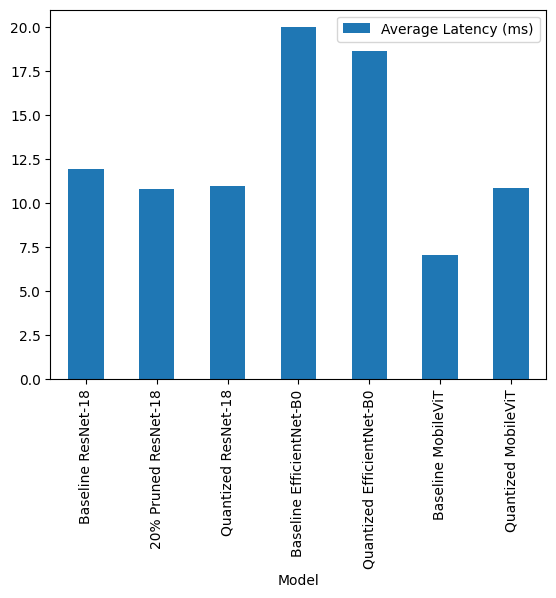

In [45]:
overall_results.plot.bar(
    x="Model",
    y="Average Latency (ms)"
)

# Figure 2

### Throughput

<Axes: xlabel='Model'>

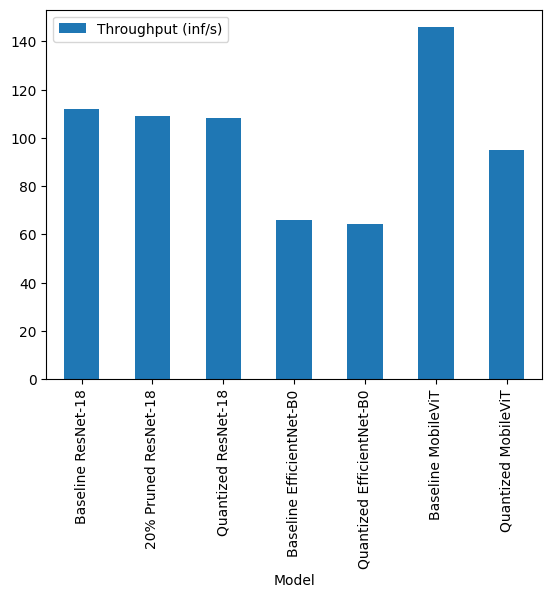

In [46]:
overall_results.plot.bar(
    x="Model",
    y="Throughput (inf/s)"
)

# Figure 3

### Energy per Million Inferences

<Axes: xlabel='Model'>

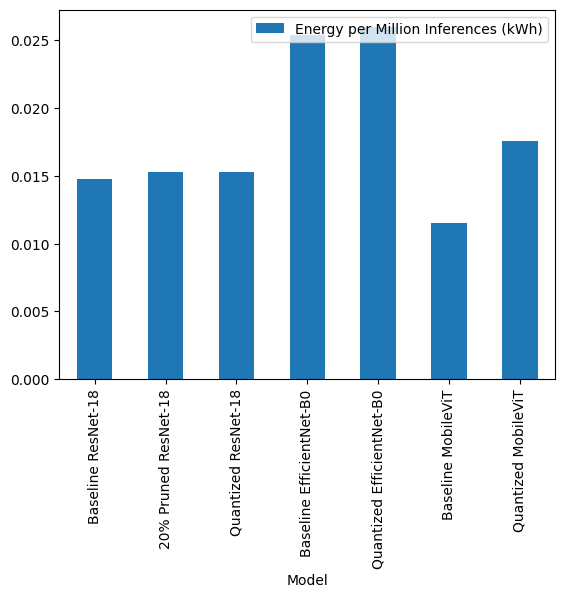

In [47]:
overall_results.plot.bar(
    x="Model",
    y="Energy per Million Inferences (kWh)"
)

# Figure 4

### CO₂ per Million Inferences

<Axes: xlabel='Model'>

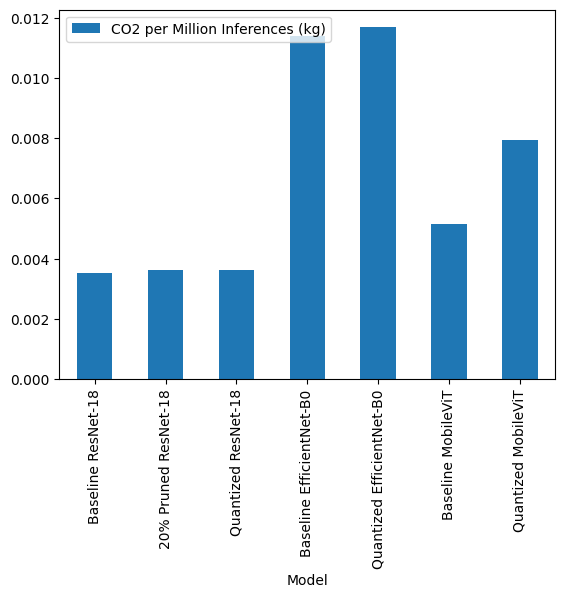

In [48]:
overall_results.plot.bar(
    x="Model",
    y="CO2 per Million Inferences (kg)"
)

In [49]:
overall_results.to_csv(
    "overall_model_comparison.csv",
    index=False
)